# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/SATReset_Tuesday.csv',
        ),
        pandas.read_csv(
            'results/SATResetTuesdayControl.csv',
        )
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'], keep = 'last')

data = data[data.problem.isin(data[data.strategy == 'SATResetAtStaleBacktrack'].problem)]

In [5]:
problems = data.problem.str[:3].value_counts().sort_index()
pandas.concat(
    [
        problems[0::3].reset_index(),
        problems[1::3].reset_index(),
        problems[2::3].reset_index(),
    ],
    axis = 1,
).fillna('')

,problem,count,problem,count,problem,count
0,AGT,432,ALG,3704,ANA,768.0
1,BIO,48,BOO,1200,CAT,1072.0
2,COL,2016,COM,600,CSR,7250.0
3,FLD,2248,GEG,8,GEO,7168.0
4,GRA,272,GRP,8528,HAL,80.0
5,HEN,544,HWC,48,HWV,2360.0
6,ITP,800,KLE,2032,KRS,2384.0
7,LAT,6064,LCL,7376,LDA,400.0
8,MED,96,MGT,1264,MSC,200.0
9,MVA,120,NLP,4496,NUM,8504.0


# Analysing

In [6]:
control = ['FirstAction', 'LeanCopCut']

In [7]:
data.groupby('strategy').problem.count()

strategy
FirstAction                 16594
LeanCopCut                  16594
SATResetAtStaleAction       16594
SATResetAtStaleBacktrack    16594
SATResetAtTwo               16594
SATResetAtTwoFixedStep      16594
SATSolve                    16212
SATSolveLiteral             16594
Name: problem, dtype: int64

In [8]:
pandas.crosstab(
    data.strategy,
    data.result,
    margins = True,
).sort_values('All')

result,Non-Theorem: no positive start clauses,Theorem,Theorem (SAT),All
strategy,,,,
FirstAction,2,1728,0,1730
SATSolve,2,0,1806,1808
LeanCopCut,2,1918,0,1920
SATSolveLiteral,2,0,2509,2511
SATResetAtStaleAction,2,0,2858,2860
SATResetAtStaleBacktrack,2,0,2865,2867
SATResetAtTwoFixedStep,2,0,2933,2935
SATResetAtTwo,2,0,2978,2980
All,16,3646,15949,19611


In [9]:
data[data.problem == 'PUZ053-1.p']

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error
37436,PUZ053-1.p,SATResetAtStaleAction,timeout,NaN,False,6276.0,90007.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:5478,forward:100926,unique:724...",NaN
37437,PUZ053-1.p,SATResetAtTwo,timeout,NaN,False,7977.0,90003.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:6562,forward:122229,unique:128...",NaN
37438,PUZ053-1.p,SATResetAtTwoFixedStep,timeout,NaN,False,7967.0,90006.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:6554,forward:122080,unique:128...",NaN
37439,PUZ053-1.p,SATResetAtStaleBacktrack,timeout,NaN,False,6276.0,90014.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:5478,forward:100926,unique:724...",NaN
103430,PUZ053-1.p,FirstAction,timeout,NaN,False,15845.0,120011.0,CNF_SAT_EPR_NEQ,False,Satisfiable,NaN,NaN,NaN
103431,PUZ053-1.p,LeanCopCut,timeout,NaN,False,15557.0,120009.0,CNF_SAT_EPR_NEQ,False,Satisfiable,NaN,NaN,NaN
103432,PUZ053-1.p,SATSolve,timeout,NaN,False,8895.0,90004.0,CNF_SAT_EPR_NEQ,False,Satisfiable,NaN,NaN,NaN
103433,PUZ053-1.p,SATSolveLiteral,timeout,NaN,False,12039.0,120000.0,CNF_SAT_EPR_NEQ,False,Satisfiable,NaN,"literal=choices:6245,forward:61132,unique:447,...",NaN


In [10]:
pandas.crosstab(
    data.result.fillna('?'),
    data.problem_declared_status,
)

problem_declared_status,ContradictoryAxioms,CounterSatisfiable,Open,Satisfiable,Theorem,Unknown,Unsatisfiable
result,,,,,,,
?,3889,5955,256,11612,43694,7054,40299
Non-Theorem: no positive start clauses,0,8,0,8,0,0,0
Theorem,38,0,0,0,2123,0,1485
Theorem (SAT),194,0,0,0,8568,0,7187


In [11]:
data[data.solved]

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error
0,AGT001+1.p,SATResetAtStaleAction,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetAtStaleAction,cuts:on,s:0...",NaN
1,AGT001+1.p,SATResetAtTwo,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetAtTwo,cuts:on,s:0,r:0,e:0...",NaN
2,AGT001+1.p,SATResetAtTwoFixedStep,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetAtTwoFixedStep,cuts:on,s:...",NaN
3,AGT001+1.p,SATResetAtStaleBacktrack,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetAtStaleBacktrack,cuts:on,...",NaN
4,AGT003+2.p,SATResetAtStaleAction,solved,Theorem (SAT),True,3200.0,13031.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:2747,forward:494217,unique:178...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
132271,TOP005-2.p,LeanCopCut,solved,Theorem,True,46241.0,22608.0,CNF_UNS_RFO_NEQ_NHN,False,Unsatisfiable,NaN,Theorem,NaN
132272,TOP005-2.p,SATSolve,solved,Theorem (SAT),True,7779.0,21093.0,CNF_UNS_RFO_NEQ_NHN,False,Unsatisfiable,NaN,Theorem (SAT); score=1.0,NaN
132273,TOP005-2.p,SATSolveLiteral,solved,Theorem (SAT),True,36879.0,37950.0,CNF_UNS_RFO_NEQ_NHN,False,Unsatisfiable,NaN,"Theorem (SAT); literal=choices:22065,forward:6...",NaN
132296,TOP026+1.p,SATSolve,solved,Theorem (SAT),True,7476.0,22217.0,FOF_THM_RFO_SEQ,False,Theorem,NaN,Theorem (SAT),NaN


In [12]:
data[data.problem_spc_tags.str.contains('FOF')].problem.str[6].value_counts()

problem
+    69861
Name: count, dtype: int64

In [13]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction                 1728
LeanCopCut                  1918
SATResetAtStaleAction       2858
SATResetAtStaleBacktrack    2865
SATResetAtTwo               2978
SATResetAtTwoFixedStep      2933
SATSolve                    1806
SATSolveLiteral             2509
dtype: int64

# Results

<Axes: xlabel='strategy'>

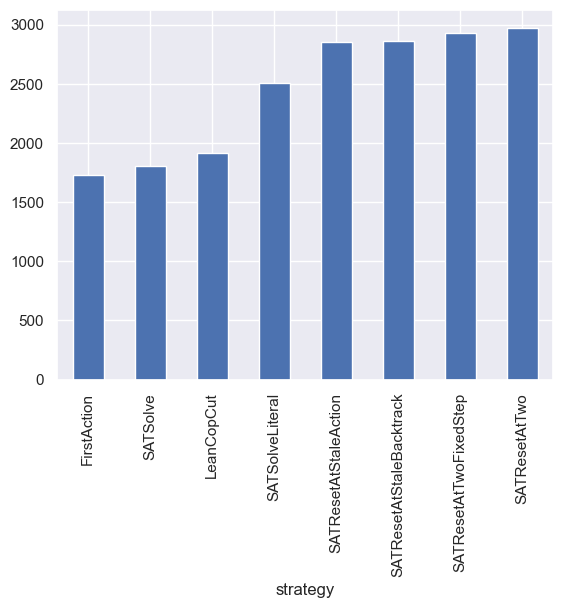

In [14]:
data[data.solved].strategy.value_counts(ascending = True).plot.bar()

In [15]:
data[data.strategy == 'SATResetAtStaleAction'].result.value_counts()

result
Theorem (SAT)                             2858
Non-Theorem: no positive start clauses       2
Name: count, dtype: int64

In [16]:
data[data.strategy == 'SATResetAtTwo'].result.value_counts()

result
Theorem (SAT)                             2978
Non-Theorem: no positive start clauses       2
Name: count, dtype: int64

In [17]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [18]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,FirstAction,LeanCopCut,SATResetAtStaleAction,SATResetAtStaleBacktrack,SATResetAtTwo,SATResetAtTwoFixedStep,SATSolve,SATSolveLiteral
strategy_left,,,,,,,,
FirstAction,16594,16594,16594,16594,16594,16594,16212,16594
LeanCopCut,16594,16594,16594,16594,16594,16594,16212,16594
SATResetAtStaleAction,16594,16594,16594,16594,16594,16594,16212,16594
SATResetAtStaleBacktrack,16594,16594,16594,16594,16594,16594,16212,16594
SATResetAtTwo,16594,16594,16594,16594,16594,16594,16212,16594
SATResetAtTwoFixedStep,16594,16594,16594,16594,16594,16594,16212,16594
SATSolve,16212,16212,16212,16212,16212,16212,16212,16212
SATSolveLiteral,16594,16594,16594,16594,16594,16594,16212,16594


<Axes: xlabel='Winner', ylabel='Loser'>

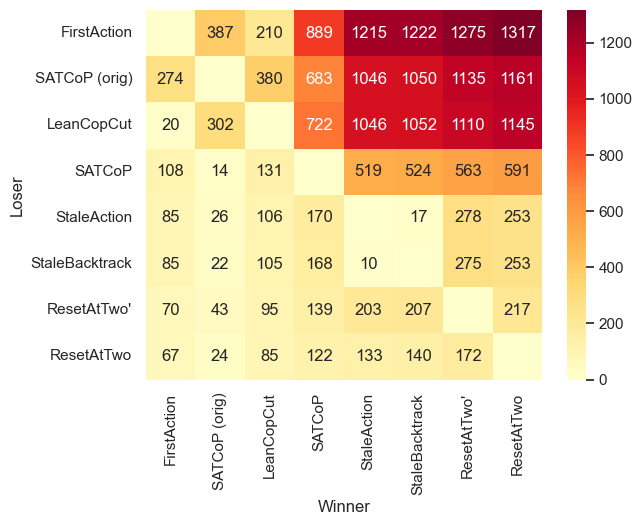

In [19]:
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
)

order = values.groupby(level = 'strategy_right').sum().sort_values().index

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = order, columns = order, fill_value = 0)
)

renamer = {
    'SATSolve': 'SATCoP (orig)',
    'SATSolveLiteral': 'SATCoP',
    'SATResetAtStaleAction': 'StaleAction',
	'SATResetAtStaleBacktrack': 'StaleBacktrack',
	'SATResetBandit': 'Bandit',
    'SATResetAtTwoFixedStep': 'ResetAtTwo\'',
    'SATResetAtTwo': 'ResetAtTwo',
}

cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = renamer).
    rename(columns = renamer)
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
)
# pyplot.title(f'Winners and losers of different SAT policies. Total of {merged.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot_29Apr.png', bbox_inches = 'tight', dpi = 400)

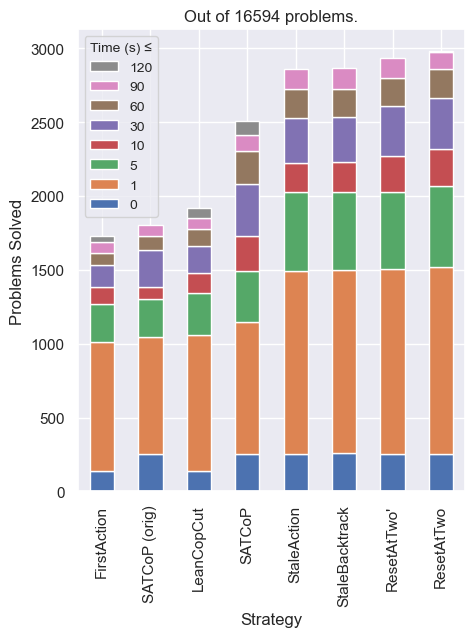

In [20]:
pyplot.rcParams["figure.figsize"] = (5,6)

times = [0, 1, 5, 10, 30, 60, 90, 120]
solved_time = Series(
    numpy.select(
        [data.solved & (data.time_ms <= 1000 * x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack().reindex(order).rename(index = renamer)
b.plot.bar(stacked = True)
pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Time (s) ≤', title_fontsize = 'small')

pyplot.title(f'Out of {data.problem.nunique()} problems.')
None

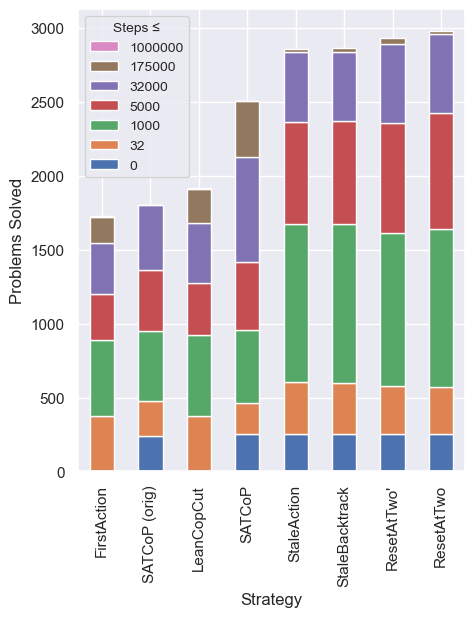

In [21]:
pyplot.rcParams["figure.figsize"] = (5,6)

times = [0, 32, 1000, 5000, 32000, 175000, 1000000]
solved_time = Series(
    numpy.select(
        [data.solved & (data.steps <= x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack().reindex(order).rename(index = renamer)
b.plot.bar(stacked = True)
pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Steps ≤', title_fontsize = 'small')

In [25]:
merged.strategy_right.unique()

array(['SATResetAtStaleAction', 'SATResetAtTwo', 'SATResetAtTwoFixedStep',
       'SATResetAtStaleBacktrack', 'FirstAction', 'LeanCopCut',
       'SATSolve', 'SATSolveLiteral'], dtype=object)

In [28]:
merged[(merged.strategy_left == 'SATSolveLiteral') & (merged.strategy_right == 'SATResetAtStaleAction') & merged.solved_right & merged.solved_left][['problem', 'steps_left', 'steps_right']]

,problem,steps_left,steps_right
529504,AGT001+1.p,0.0,0.0
529536,AGT003+2.p,10678.0,3200.0
529696,AGT016+1.p,7669.0,5332.0
529856,AGT001+2.p,0.0,0.0
529888,AGT004+1.p,7319.0,1871.0
...,...,...,...
1053750,TOP004-2.p,340.0,8.0
1054582,TOP002-2.p,10.0,6.0
1054838,TOP027+1.p,8975.0,2698.0
1055478,TOP005-2.p,36879.0,3419.0


In [35]:
merged.columns

Index(['problem', 'strategy_left', 'status_left', 'result_left', 'solved_left',
       'steps_left', 'time_ms_left', 'problem_spc_tags_left',
       'problem_typed_left', 'problem_declared_status_left',
       'problem_declared_status_kind_left', 'info_left', 'error_left',
       'strategy_right', 'status_right', 'result_right', 'solved_right',
       'steps_right', 'time_ms_right', 'problem_spc_tags_right',
       'problem_typed_right', 'problem_declared_status_right',
       'problem_declared_status_kind_right', 'info_right', 'error_right'],
      dtype='object')

In [37]:
merged[
    (merged.strategy_left == 'FirstAction') &
    (merged.strategy_right == 'SATSolve') &
    merged.solved_right &
    merged.solved_left &
    (merged.steps_right == 0) &
    (merged.steps_left < 10000)
    ][['problem', 'time_ms_left', 'steps_left', 'time_ms_right', 'steps_right']].sort_values('steps_left', ascending = False)

,problem,time_ms_left,steps_left,time_ms_right,steps_right
537422,ALG039+1.p,17525.0,7166.0,0.0,0.0
674020,HWV095-1.p,21538.0,5943.0,0.0,0.0
675876,HWV093-1.p,23168.0,5943.0,0.0,0.0
1021700,SYN288-1.p,4485.0,5003.0,0.0,0.0
1036996,SYN295-1.p,4888.0,5003.0,0.0,0.0
...,...,...,...,...,...
1030340,SYN404+1.p,0.0,2.0,0.0,0.0
1037860,SYN389+1.p,0.0,2.0,0.0,0.0
1037796,SYN379+1.p,0.0,2.0,0.0,0.0
1037988,SYN410+1.p,0.0,2.0,0.0,0.0
